# Wine Quality Prediction

# #1 Importing Libraries

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# #2 Data Loading

In [73]:
df = pd.read_csv(r'C:\Users\neo28\OneDrive\Рабочий стол\datasets\winequality-red.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [74]:
df.shape

(1599, 12)

In [75]:
# Missing values and duplicates
print('Missing values:', df.isnull().sum().sum())
print(f'Duplicates: {df.duplicated().sum()}')

Missing values: 0
Duplicates: 240


In [76]:
# Drop duplicates
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Dropped {n_before - len(df)} duplicates. Remaining: {len(df)}')

Dropped 240 duplicates. Remaining: 1359


# #3 Exploratory Data Analysis (EDA)

In [77]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


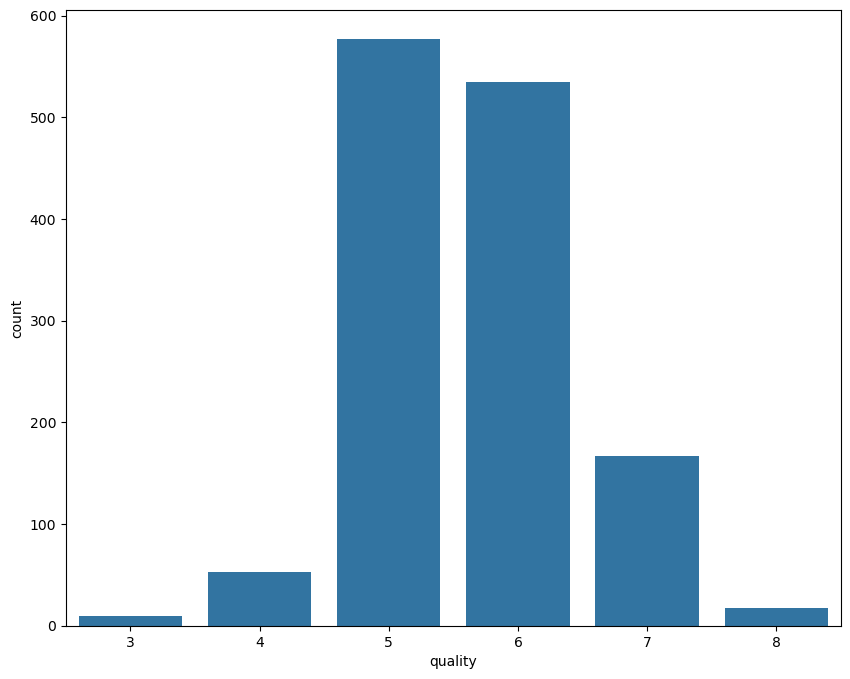

In [78]:
# Distribution of target variables
fig = plt.figure(figsize=(10,8))
sns.barplot(df['quality'].value_counts())
plt.xlabel('quality')
plt.ylabel('count')
plt.show()

Analyzing Feature Distributions by Wine Quality


In this step, we create boxplots to compare the distributions of each feature across different wine quality levels. This helps us identify differences in feature values, detect potential outliers, and understand which features may be related to wine quality.

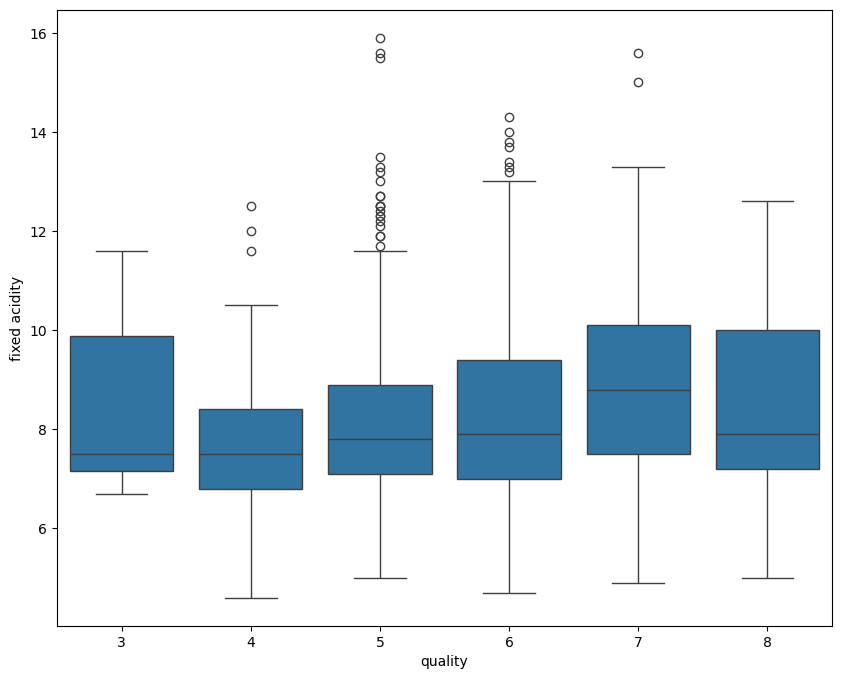

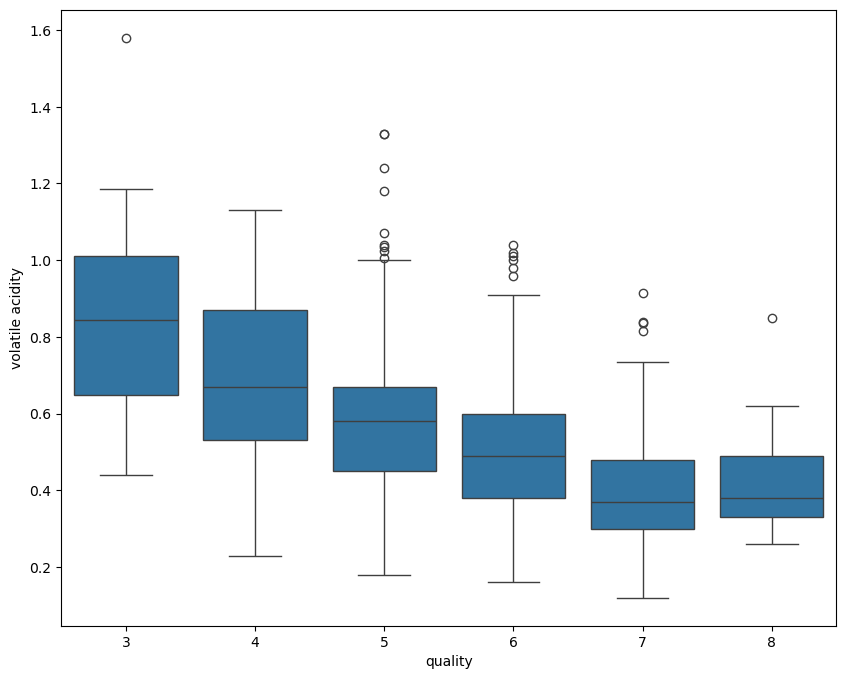

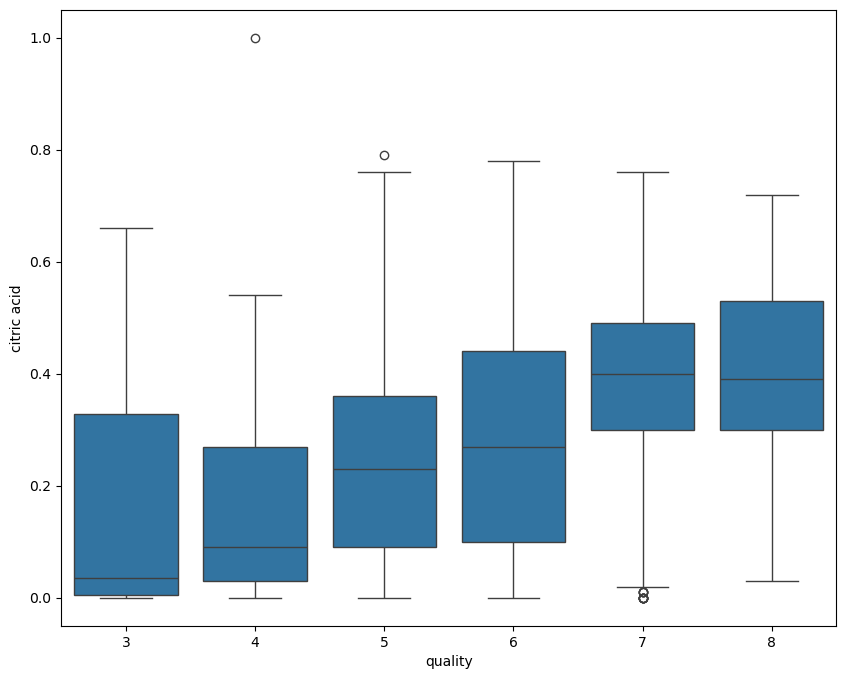

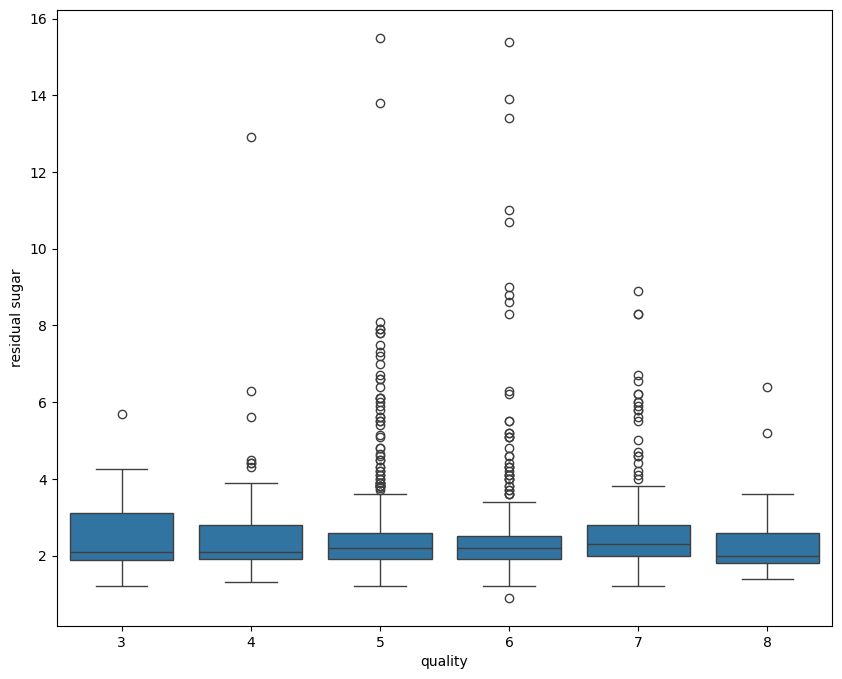

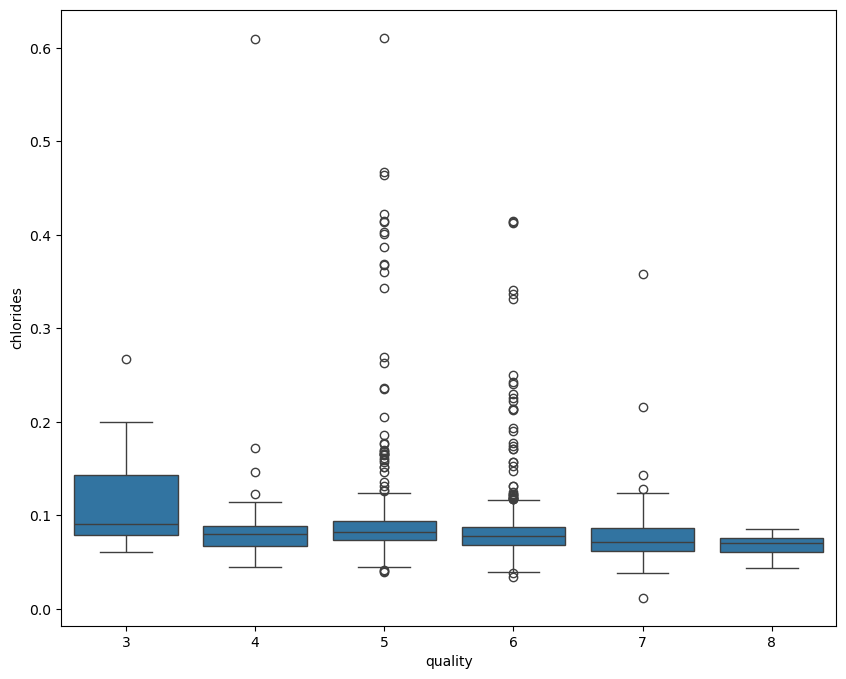

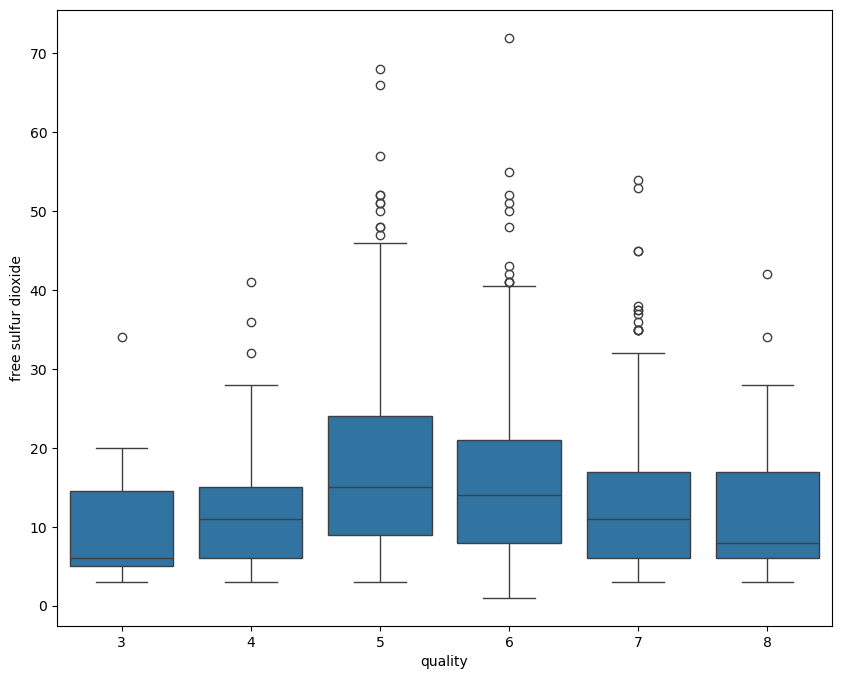

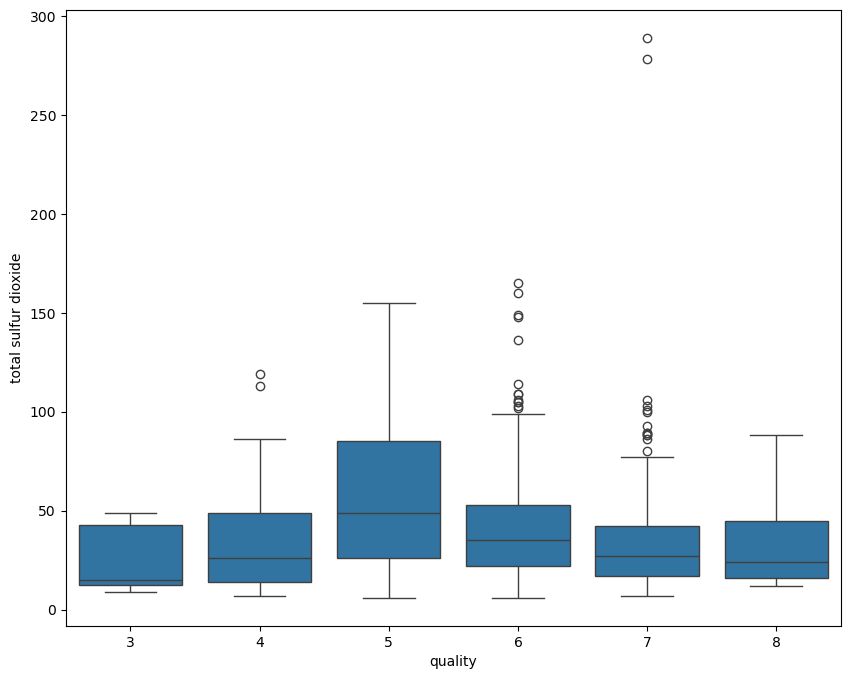

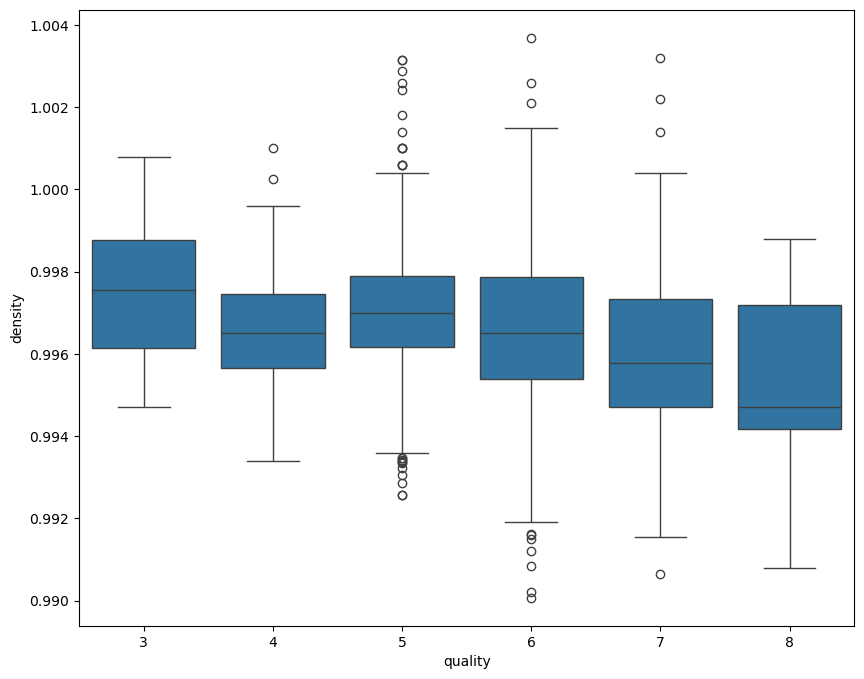

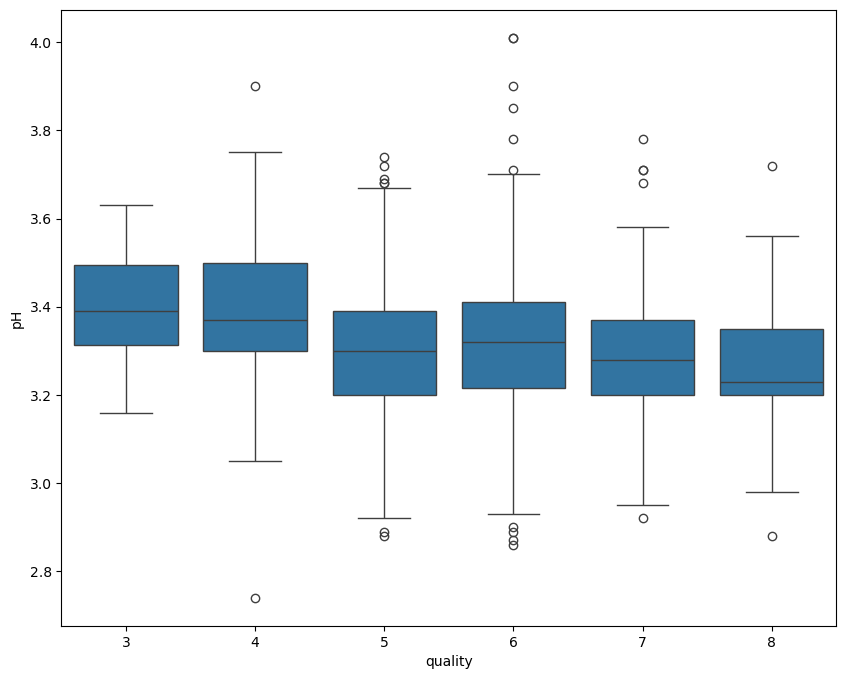

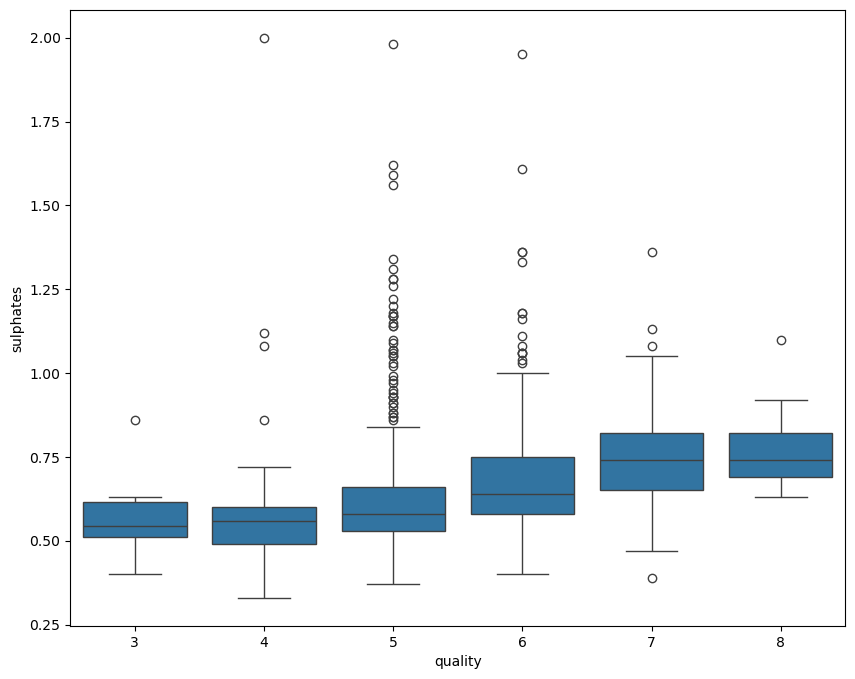

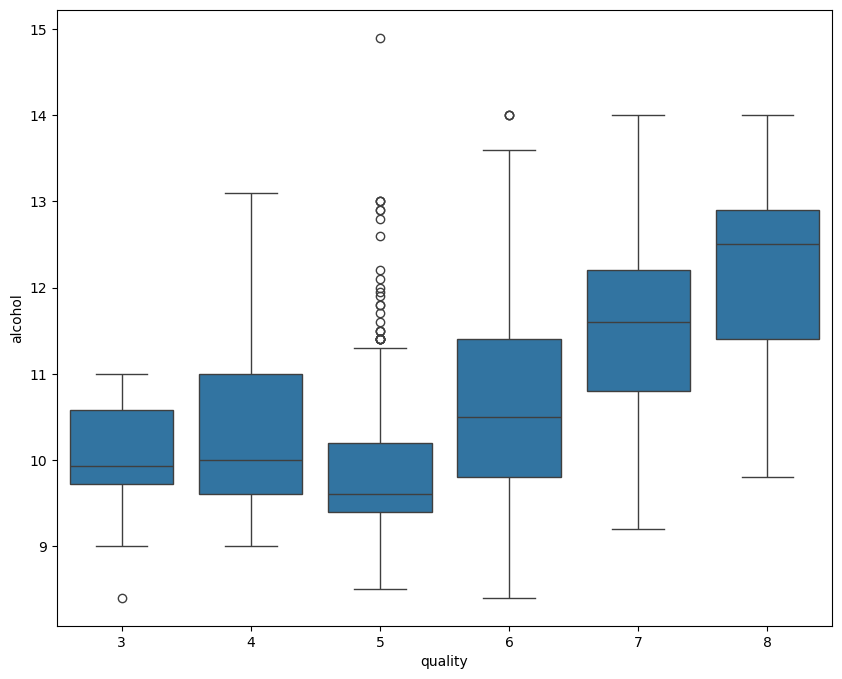

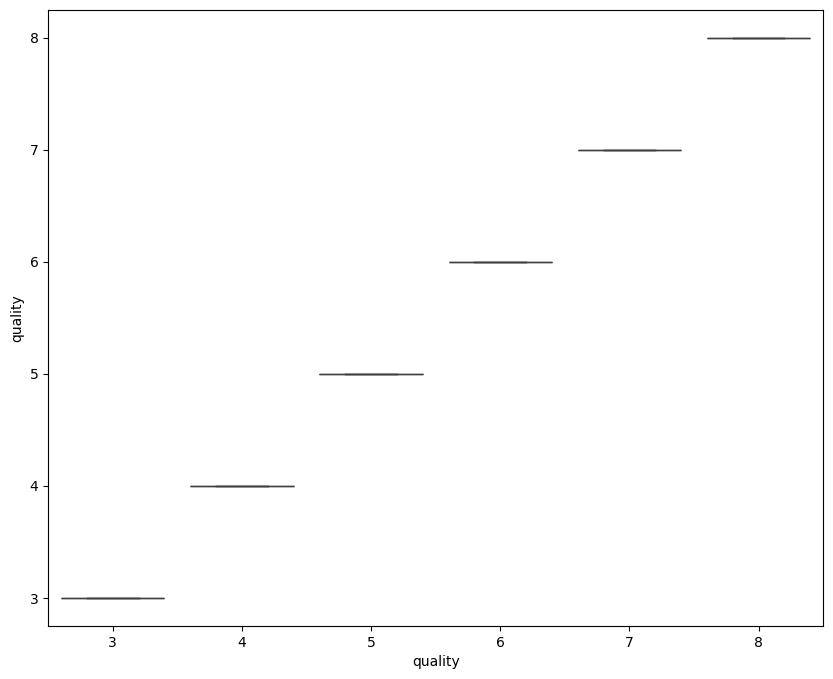

In [79]:
for col in df:
    fig = plt.figure(figsize=(10, 8))
    sns.boxplot(data=df, y=col, x=df['quality'].astype('category'))

# #4 Data Preprocessing

Identifying Highly Correlated Features

In this step, we calculate the absolute correlation coefficients between numerical features to identify the strongest relationships in the dataset.

In [80]:
def get_redundant_pairs(df):
    pairs_to_drop = set()
    cols = df.columns
    for i in range(0, df.shape[1]):
        for j in range(0, i+1):
            pairs_to_drop.add((cols[i], cols[j]))
    return pairs_to_drop

def get_top_abs_correlations(df, n=5):
    au_corr = df.corr().abs().unstack()#.unstack() — "разворачивает" двумерную таблицу в одномерный объект Series
    labels_to_drop = get_redundant_pairs(df)
    au_corr = au_corr.drop(labels=labels_to_drop).sort_values(ascending=False)#удаляет избыточные пары (диагональ и повторы)
    return au_corr[0:n]

print("Top Absolute Correlations")
print(get_top_abs_correlations(df, 15))

Top Absolute Correlations
fixed acidity        pH                      0.686685
                     density                 0.670195
                     citric acid             0.667437
free sulfur dioxide  total sulfur dioxide    0.667246
volatile acidity     citric acid             0.551248
citric acid          pH                      0.550310
density              alcohol                 0.504995
alcohol              quality                 0.480343
volatile acidity     quality                 0.395214
chlorides            sulphates               0.394557
citric acid          density                 0.357962
density              pH                      0.355617
citric acid          sulphates               0.326062
residual sugar       density                 0.324522
chlorides            pH                      0.270893
dtype: float64


Establishing a Baseline Model

We create a baseline regression model using DummyRegressor, which always predicts the mean target value from the training data.

In [81]:
X = df.drop('quality', axis=1)
y = df['quality']

In [82]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

baseline = DummyRegressor(strategy="mean")

cv_baseline = cross_validate(
    baseline, X, y,
    cv=5,
    scoring="neg_mean_squared_error"
)

print("Baseline MSE:", -cv_baseline["test_score"].mean())

Baseline MSE: 0.6965698000831888


# #5 Model Training

In [83]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=51)

Comparing Linear Regression Models Using Cross-Validation

We compare three regression models: Linear Regression, Lasso, and Ridge. Each model is combined with StandardScaler in a pipeline to standardize the features before training.

In [84]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso, Ridge

models = {'LinearRegression': LinearRegression(), 'Lasso': Lasso(max_iter=100000), 'Ridge': Ridge()}

scorings = {'mae': 'neg_mean_absolute_error',
           'mse': 'neg_mean_squared_error',
           'r2': 'r2'}

for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    for score_name, scoring in scorings.items():
        cv_result = cross_validate(pipe, X_train, y_train, cv=5, scoring=scoring)
        score = cv_result['test_score'].mean()
        if score_name in ['mae', 'mse']:
            score = -score
        print(f'{name} with metrick {score_name}: {score:.4f}')
    


LinearRegression with metrick mae: 0.5165
LinearRegression with metrick mse: 0.4494
LinearRegression with metrick r2: 0.3415
Lasso with metrick mae: 0.6970
Lasso with metrick mse: 0.6855
Lasso with metrick r2: -0.0030
Ridge with metrick mae: 0.5165
Ridge with metrick mse: 0.4493
Ridge with metrick r2: 0.3416


# #6 Hyperparameter Tuning

In [85]:
alphas = np.logspace(start=-3, stop=3, num=30)
alphas

array([1.00000000e-03, 1.61026203e-03, 2.59294380e-03, 4.17531894e-03,
       6.72335754e-03, 1.08263673e-02, 1.74332882e-02, 2.80721620e-02,
       4.52035366e-02, 7.27895384e-02, 1.17210230e-01, 1.88739182e-01,
       3.03919538e-01, 4.89390092e-01, 7.88046282e-01, 1.26896100e+00,
       2.04335972e+00, 3.29034456e+00, 5.29831691e+00, 8.53167852e+00,
       1.37382380e+01, 2.21221629e+01, 3.56224789e+01, 5.73615251e+01,
       9.23670857e+01, 1.48735211e+02, 2.39502662e+02, 3.85662042e+02,
       6.21016942e+02, 1.00000000e+03])

Hyperparameter Tuning for Lasso Regression

In [86]:
from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV
kf = KFold(n_splits=5, shuffle=True, random_state=3)
param_grid = {'lasso__alpha' : alphas}
lasso_pipe = make_pipeline(StandardScaler(), Lasso())
search_cv_lasso = GridSearchCV(lasso_pipe, param_grid, cv=kf, scoring='neg_mean_squared_error')
search_cv_lasso.fit(X_train, y_train)
print(f'Best paramenetr: {-search_cv_lasso.best_score_:.4f}')
print(f'Best alpha: {search_cv_lasso.best_params_}')

Best paramenetr: 0.4451
Best alpha: {'lasso__alpha': np.float64(0.010826367338740546)}


In [87]:
lasso_pipe.set_params(lasso__alpha=search_cv_lasso.best_params_['lasso__alpha'])

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lasso', Lasso(alpha=np.float64(0.010826367338740546)))])

In [88]:
param_grid = {'ridge__alpha' : alphas}
ridge_pipe = make_pipeline(StandardScaler(), Ridge())
search_cv_ridge = GridSearchCV(ridge_pipe, param_grid, cv=kf, scoring='neg_mean_squared_error')
search_cv_ridge.fit(X_train, y_train)
print(f'Best paramenetr: {-search_cv_ridge.best_score_:.4f}')
print(f'Best alpha: {search_cv_ridge.best_params_}')

Best paramenetr: 0.4461
Best alpha: {'ridge__alpha': np.float64(22.122162910704503)}


In [89]:
ridge_pipe.set_params(ridge__alpha=search_cv_ridge.best_params_['ridge__alpha'])

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridge', Ridge(alpha=np.float64(22.122162910704503)))])

# №7 Model Evaluation

In [90]:
cv_result_lasso = cross_validate(lasso_pipe, X_train, y_train, cv=kf, scoring='neg_mean_squared_error', return_train_score=True)
print(f'MSE train: {-np.mean(cv_result_lasso['train_score']).round(3)}')
print(f'MSE test: {-np.mean(cv_result_lasso['test_score']).round(3)}')

MSE train: 0.435
MSE test: 0.445


In [91]:
cv_result_ridge = cross_validate(ridge_pipe, X_train, y_train, cv=kf, scoring='neg_mean_squared_error', return_train_score=True)
print(f'MSE train: {-np.mean(cv_result_ridge['train_score']).round(3)}')
print(f'MSE test: {-np.mean(cv_result_ridge['test_score']).round(3)}')

MSE train: 0.434
MSE test: 0.446


In [92]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_lasso = search_cv_lasso.best_estimator_

y_pred = best_lasso.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
print(f"R2: {r2_score(y_test, y_pred):.4f}")

MAE: 0.5063
MSE: 0.4196
R2: 0.3541


In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_ridge = search_cv_ridge.best_estimator_

y_pred_ridge = best_ridge.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, y_pred_ridge):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_ridge):.4f}")
print(f"R2: {r2_score(y_test, y_pred_ridge):.4f}")

MAE: 0.5073
MSE: 0.4215
R2: 0.3511


# #8 Conclusion

In [94]:
print(f"MAE Lasso: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"MSE Lasso: {mean_squared_error(y_test, y_pred):.4f}")
print(f"R2 Lasso: {r2_score(y_test, y_pred):.4f}")

MAE Lasso: 0.5063
MSE Lasso: 0.4196
R2 Lasso: 0.3541


Visualizing Actual vs. Predicted Values

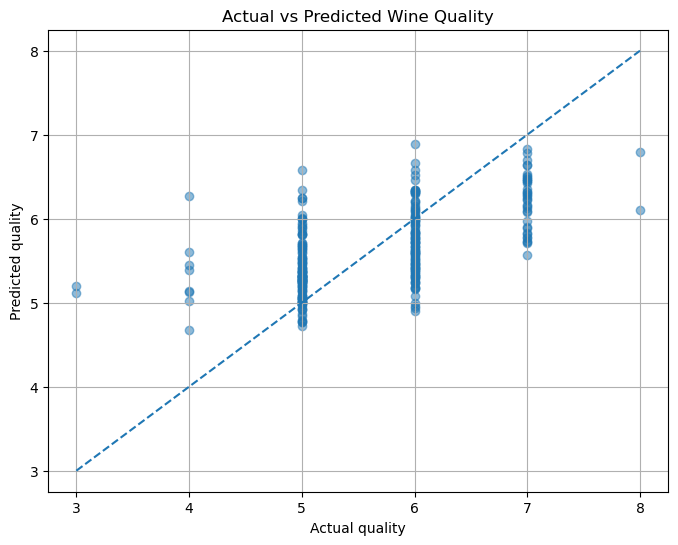

In [95]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual quality')
plt.ylabel('Predicted quality')
plt.title('Actual vs Predicted Wine Quality')
plt.grid(True)
plt.show()

Residual Analysis

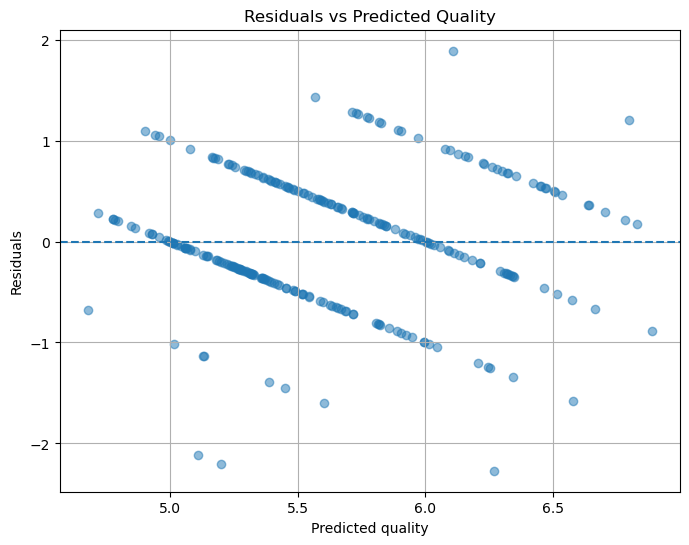

In [96]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted quality')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Quality')
plt.grid(True)
plt.show()

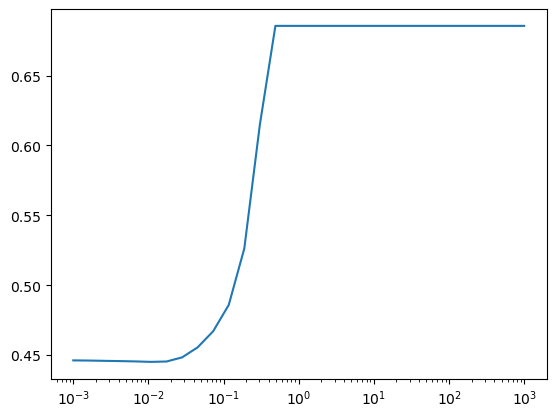

In [97]:
results = pd.DataFrame(search_cv_lasso.cv_results_)

plt.semilogx(results['param_lasso__alpha'].astype(float), -results['mean_test_score'])

# #9 Feature Selection and Transformation Experiments

In [98]:
from sklearn.feature_selection import VarianceThreshold

cutter = VarianceThreshold(threshold=0.1)
cutter.fit(df)

cutter.get_feature_names_out()

array(['fixed acidity', 'residual sugar', 'free sulfur dioxide',
       'total sulfur dioxide', 'alcohol', 'quality'], dtype=object)

In [99]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


In [100]:
df_cutted = df.copy()

In [101]:
df_cutted = df_cutted.drop(['volatile acidity', 'citric acid', 'chlorides', 'density', 'pH', 'sulphates'], axis=1)

In [102]:
df_cutted.head()

,fixed acidity,residual sugar,free sulfur dioxide,total sulfur dioxide,alcohol,quality
0,7.4,1.9,11.0,34.0,9.4,5
1,7.8,2.6,25.0,67.0,9.8,5
2,7.8,2.3,15.0,54.0,9.8,5
3,11.2,1.9,17.0,60.0,9.8,6
4,7.4,1.8,13.0,40.0,9.4,5


In [103]:
X_new = df_cutted.drop('quality', axis=1)
y_new = df_cutted['quality']

In [104]:
model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=67)
cv_result = cross_validate(model, X_new, y_new, cv=kf, scoring='neg_mean_squared_error', return_train_score=True)
print(f'MSE train with only LinearRegression: {-np.mean(cv_result['train_score']).round(3)}')
print(f'MSE test with only LinearRegression: {-np.mean(cv_result['test_score']).round(3)}')

MSE train with only LinearRegression: 0.501
MSE test with only LinearRegression: 0.505


In [105]:
model_lasso = Lasso(max_iter=100000)
cv_result_lasso = cross_validate(model_lasso, X_new, y_new, cv=kf, scoring='neg_mean_squared_error', return_train_score=True)
print(f'MSE train with only Lasso: {-np.mean(cv_result_lasso['train_score']).round(3)}')
print(f'MSE test with only Lasso: {-np.mean(cv_result_lasso['test_score']).round(3)}')

MSE train with only Lasso: 0.657
MSE test with only Lasso: 0.659


In [106]:
pipe_lasso = make_pipeline(StandardScaler(), Lasso(max_iter=100000))
cv_result_lasso = cross_validate(pipe_lasso, X_new, y_new, cv=kf, scoring='neg_mean_squared_error', return_train_score=True)
print(f'MSE train with StandardScaler and Lasso: {-np.mean(cv_result_lasso['train_score']).round(3)}')
print(f'MSE test with StandardScaler and Lasso: {-np.mean(cv_result_lasso['test_score']).round(3)}')

MSE train with StandardScaler and Lasso: 0.678
MSE test with StandardScaler and Lasso: 0.679


In [109]:
param_grid = {'lasso__alpha' : alphas}
search_cv = GridSearchCV(pipe_lasso, param_grid, cv=kf, scoring='neg_mean_squared_error')
search_cv.fit(X, y)
print(f'Best paramenetr: {-search_cv.best_score_:.5f}')

Best paramenetr: 0.44038


In [110]:
data = pd.concat((X, y), axis=1)

In [111]:
top_quantile = data['quality'].quantile(0.975)
low_quantile = data['quality'].quantile(0.025)


In [112]:
print(f'Top 2.5% of target: {top_quantile.round(2)}')
print(f'Top 97.5% of target: {low_quantile.round(2)}')


Top 2.5% of target: 7.0
Top 97.5% of target: 4.0


In [113]:
data = data[(data['quality'] > low_quantile) & (data['quality'] < top_quantile)]

In [114]:
X_new = data.drop('quality', axis=1)
y_new = data['quality']

In [115]:
new_kf = KFold(n_splits=5, shuffle=True, random_state=67)
search = GridSearchCV(pipe_lasso, param_grid, cv=new_kf, scoring='neg_mean_squared_error')
search.fit(X_new, y_new)
print(f'Best paramenetr: {search.best_score_:.5f}')
print(search.best_params_)

Best paramenetr: -0.19639
{'lasso__alpha': np.float64(0.006723357536499335)}


In [116]:
pipe_lasso.set_params(lasso__alpha=search.best_params_['lasso__alpha'])

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lasso',
                 Lasso(alpha=np.float64(0.006723357536499335),
                       max_iter=100000))])

In [117]:
cv_result_pipe = cross_validate(pipe_lasso, X_new, y_new, cv=new_kf, scoring='neg_mean_squared_error', return_train_score=True)
print(f'MSE train: {-np.mean(cv_result_pipe['train_score']).round(3)}')
print(f'MSE test: {-np.mean(cv_result_pipe['test_score']).round(3)}')

MSE train: 0.192
MSE test: 0.196
